# Lab Week 3 – Decision Trees, Random Forests, Ensemble Learning

In this week's lab, we will be implementing Decison Trees, Random Forests and Ensemble methods

In [1]:
!pip install numpy


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [1]:
#Let's start by importing some necessary packages

import numpy as np
import pandas as pd
import sklearn as sk
import os

# To plot pretty figures
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('axes', labelsize=14)
mpl.rc('xtick', labelsize=12)
mpl.rc('ytick', labelsize=12)

# Where to save the figures
PROJECT_ROOT_DIR = "."
CHAPTER_ID = "decision_trees"
IMAGES_PATH = os.path.join(PROJECT_ROOT_DIR, "images", CHAPTER_ID)
os.makedirs(IMAGES_PATH, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = os.path.join(IMAGES_PATH, fig_id + "." + fig_extension)
    print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

# Decision Trees

Let's start by implementing Decision Trees on the Iris dataset

In [2]:
# Uncomment the code below and run

# from sklearn.datasets import load_iris #import Iris dataset
# from sklearn.tree import DecisionTreeClassifier #import Decision Tree classifier

# iris = load_iris()
# X = iris.data[:, 2:] # petal length and width
# y = iris.target

# tree_clf = DecisionTreeClassifier(max_depth=2, random_state=42)
# tree_clf.fit(X, y)
from sklearn.datasets import load_iris  # import Iris dataset
from sklearn.tree import DecisionTreeClassifier  # import Decision Tree classifier

iris = load_iris()
X = iris.data[:, 2:]  # petal length and width
y = iris.target

tree_clf = DecisionTreeClassifier(max_depth=2, random_state=42)
tree_clf.fit(X, y)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

We set two parameters, `max_depth` and `random_state`. We use the default settings for the rest of the parameters. 

Scikit-Learn uses the **Classification and Regression Tree (CART) algorithm** to train Decision Trees (also called “growing” trees). CART algorithm is a greedy algorithm: it greedily searches for an optimum split at the top level, then repeats the process at each subsequent level. It does not check whether or not the split will lead to the lowest possible impurity several levels down. A greedy algorithm often produces a solution that’s reasonably good but not guaranteed to be optimal.

You can visualize the trained Decision Tree by first using the `export_graphviz()` method to output a graph definition file called iris_tree.dot

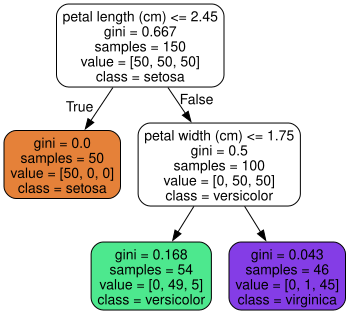

In [12]:
# code generates Iris Decision Tree - Uncomment the code below and run

from graphviz import Source
from sklearn.tree import export_graphviz

export_graphviz(
     tree_clf,
     out_file=os.path.join(IMAGES_PATH, "iris_tree.dot"),
     feature_names=iris.feature_names[2:],
     class_names=iris.target_names,
     rounded=True,
     filled=True
     )
Source.from_file(os.path.join(IMAGES_PATH, "iris_tree.dot"))

## Making Predictions

Let’s see how the tree represented above makes predictions. Suppose you find an iris flower and you want to classify it. You start at the root node (depth 0, at the top): this node asks whether the flower’s petal length is smaller than 2.45 cm. If it is, then you move down to the root’s left child node (depth 1, left). In this case, it is a leaf node (i.e., it does not have any child nodes), so it does not ask any questions: simply look at the predicted class for that node, and the Decision Tree predicts that your flower is an Iris setosa ($class=setosa$).

Suppose you find another flower, and this time the petal length is greater than 2.45 cm. You must move down to the root’s right child node (depth 1, right), which is not a leaf node, so the node asks another question: is the petal width smaller than 1.75 cm? If it is, then your flower is most likely an Iris versicolor (depth 2, left). If not, it is likely an Iris virginica (depth 2, right). 

A node’s `samples` attribute counts how many training instances it applies to. For example, 100 training instances have a petal length greater than 2.45 cm (depth 1, right), and of those 100, 54 have a petal width smaller than 1.75 cm (depth 2, left). A node’s `value` attribute tells you how many training instances of each class this node applies to: for example, the bottom-right node applies to 0 Iris setosa, 1 Iris versicolor, and 45 Iris virginica. Finally, a node’s `gini` attribute measures its impurity: a node is “pure” (gini=0) if all training instances it applies to belong to the same class. For example, since the depth-1 left node applies only to Iris setosa training instances, it is pure and its gini score is 0. The equation below shows how the training algorithm computes the gini score $G_i$ of the $i^{th}$ node. The depth-2 left node has a gini score equal to $1 – (0/54)^2 – (49/54)^2 – (5/54)^2 ≈ 0.168$.

**Gini impurity**: $G_i = 1 - \sum_{k=1}^{n} p_{i,k}^2$ where $p_{i,k}$ is the ratio of class $k$ instances among the training instances in the $i^{th}$ node.

Saving figure decision_tree_decision_boundaries_plot


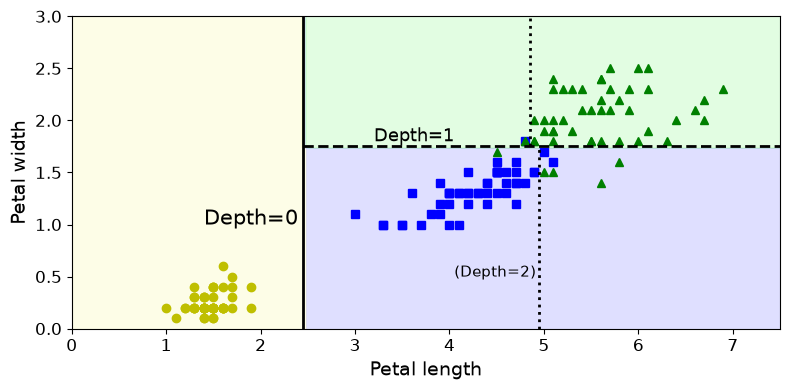

In [13]:
# Code to generate the Decision Tree's decision boundaries - uncomment and run

from matplotlib.colors import ListedColormap

def plot_decision_boundary(clf, X, y, axes=[0, 7.5, 0, 3], iris=True, legend=False, plot_training=True):
    x1s = np.linspace(axes[0], axes[1], 100)
    x2s = np.linspace(axes[2], axes[3], 100)
    x1, x2 = np.meshgrid(x1s, x2s)
    X_new = np.c_[x1.ravel(), x2.ravel()]
    y_pred = clf.predict(X_new).reshape(x1.shape)
    custom_cmap = ListedColormap(['#fafab0','#9898ff','#a0faa0'])
    plt.contourf(x1, x2, y_pred, alpha=0.3, cmap=custom_cmap)     
    if not iris:
        custom_cmap2 = ListedColormap(['#7d7d58','#4c4c7f','#507d50'])
        plt.contour(x1, x2, y_pred, cmap=custom_cmap2, alpha=0.8)
    if plot_training:
        plt.plot(X[:, 0][y==0], X[:, 1][y==0], "yo", label="Iris setosa")
        plt.plot(X[:, 0][y==1], X[:, 1][y==1], "bs", label="Iris versicolor")
        plt.plot(X[:, 0][y==2], X[:, 1][y==2], "g^", label="Iris virginica")
        plt.axis(axes)
    if iris:
        plt.xlabel("Petal length", fontsize=14)
        plt.ylabel("Petal width", fontsize=14)
    else:
        plt.xlabel(r"$x_1$", fontsize=18)
        plt.ylabel(r"$x_2$", fontsize=18, rotation=0)
    if legend:
        plt.legend(loc="lower right", fontsize=14)

plt.figure(figsize=(8, 4))
plot_decision_boundary(tree_clf, X, y)
plt.plot([2.45, 2.45], [0, 3], "k-", linewidth=2)
plt.plot([2.45, 7.5], [1.75, 1.75], "k--", linewidth=2)
plt.plot([4.95, 4.95], [0, 1.75], "k:", linewidth=2)
plt.plot([4.85, 4.85], [1.75, 3], "k:", linewidth=2)
plt.text(1.40, 1.0, "Depth=0", fontsize=15)
plt.text(3.2, 1.80, "Depth=1", fontsize=13)
plt.text(4.05, 0.5, "(Depth=2)", fontsize=11)

save_fig("decision_tree_decision_boundaries_plot")
plt.show()

## Estimating Probabilities

A Decision Tree can also estimate the probability that an instance belongs to a particular class k. First, it traverses the tree to find the leaf node for this instance, and then it returns the ratio of training instances of class k in this node. 

For example, suppose you have found a flower whose petals are 5 cm long and 1.5 cm wide. The corresponding leaf node is the depth-2 left node, so the Decision Tree should output the following probabilities: 0% for Iris setosa (0/54), 90.7% for Iris versicolor (49/54), and 9.3% for Iris virginica (5/54). And if you ask it to predict the class, it should output Iris versicolor (class 1) because it has the highest probability. Let’s check this:

In [14]:
 tree_clf.predict_proba([[5, 1.5]])

array([[0.        , 0.90740741, 0.09259259]])

In [15]:
tree_clf.predict([[5, 1.5]])

array([1])

Training the same model on the same data may produce a very different model every time, since the CART training algorithm used by Scikit-Learn is stochastic. To show this, we will set random_state to a different value than earlier:

In [18]:
tree_clf_tweaked = DecisionTreeClassifier(max_depth=2, random_state=40)
tree_clf_tweaked.fit(X, y)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",40
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

Saving figure decision_tree_decision_boundaries_plot


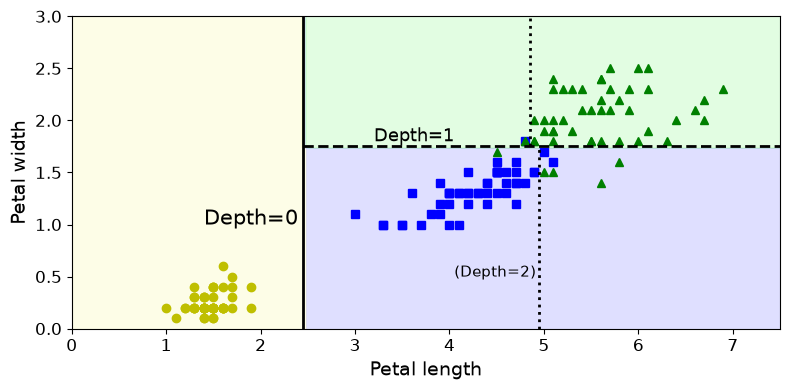

In [20]:
# Code to generate the Decision Tree's decision boundaries - uncomment and run

from matplotlib.colors import ListedColormap

def plot_decision_boundary(clf, X, y, axes=[0, 7.5, 0, 3], iris=True, legend=False, plot_training=True):
    x1s = np.linspace(axes[0], axes[1], 100)
    x2s = np.linspace(axes[2], axes[3], 100)
    x1, x2 = np.meshgrid(x1s, x2s)
    X_new = np.c_[x1.ravel(), x2.ravel()]
    y_pred = clf.predict(X_new).reshape(x1.shape)
    custom_cmap = ListedColormap(['#fafab0','#9898ff','#a0faa0'])
    plt.contourf(x1, x2, y_pred, alpha=0.3, cmap=custom_cmap)     
    if not iris:
        custom_cmap2 = ListedColormap(['#7d7d58','#4c4c7f','#507d50'])
        plt.contour(x1, x2, y_pred, cmap=custom_cmap2, alpha=0.8)
    if plot_training:
        plt.plot(X[:, 0][y==0], X[:, 1][y==0], "yo", label="Iris setosa")
        plt.plot(X[:, 0][y==1], X[:, 1][y==1], "bs", label="Iris versicolor")
        plt.plot(X[:, 0][y==2], X[:, 1][y==2], "g^", label="Iris virginica")
        plt.axis(axes)
    if iris:
        plt.xlabel("Petal length", fontsize=14)
        plt.ylabel("Petal width", fontsize=14)
    else:
        plt.xlabel(r"$x_1$", fontsize=18)
        plt.ylabel(r"$x_2$", fontsize=18, rotation=0)
    if legend:
        plt.legend(loc="lower right", fontsize=14)

plt.figure(figsize=(8, 4))
plot_decision_boundary(tree_clf_tweaked, X, y)
plt.plot([2.45, 2.45], [0, 3], "k-", linewidth=2)
plt.plot([2.45, 7.5], [1.75, 1.75], "k--", linewidth=2)
plt.plot([4.95, 4.95], [0, 1.75], "k:", linewidth=2)
plt.plot([4.85, 4.85], [1.75, 3], "k:", linewidth=2)
plt.text(1.40, 1.0, "Depth=0", fontsize=15)
plt.text(3.2, 1.80, "Depth=1", fontsize=13)
plt.text(4.05, 0.5, "(Depth=2)", fontsize=11)

save_fig("decision_tree_decision_boundaries_plot")
plt.show()

In [9]:
tree_clf_tweaked.predict_proba([[5, 1.5]])
tree_clf.predict([[5, 1.5]])

## Regularization parameters

Decision Trees make very few assumptions about the training data (as opposed to linear models, which assume that the data is linear, for example). If left unconstrained, the tree structure will adapt itself to the training data, fitting it very closely—indeed, most likely overfitting it.

To avoid overfitting the training data, you need to restrict the Decision Tree’s freedom during training. As you know by now, this is called regularization. The regularization hyperparameters depend on the algorithm used, but generally you can at least restrict the maximum depth of the Decision Tree. In Scikit-Learn, this is controlled by the `max_depth` hyperparameter (the default value is None, which means unlimited). Reducing max_depth will regularize the model and thus reduce the risk of overfitting.

The `DecisionTreeClassifier` class has a few other parameters that similarly restrict the shape of the Decision Tree: `min_samples_split` (the minimum number of samples a node must have before it can be split), `min_samples_leaf` (the minimum number of samples a leaf node must have), `min_weight_fraction_leaf` (same as min_samples_leaf but expressed as a fraction of the total number of weighted instances), `max_leaf_nodes` (the maximum number of leaf nodes), and `max_features` (the maximum number of features that are evaluated for splitting at each node). 

**Note** - Increasing `min_*` hyperparameters or reducing `max_*` hyperparameters will regularize the model.

Below, we see how regularization works using `min_samples_leaf`.

Saving figure min_samples_leaf_plot


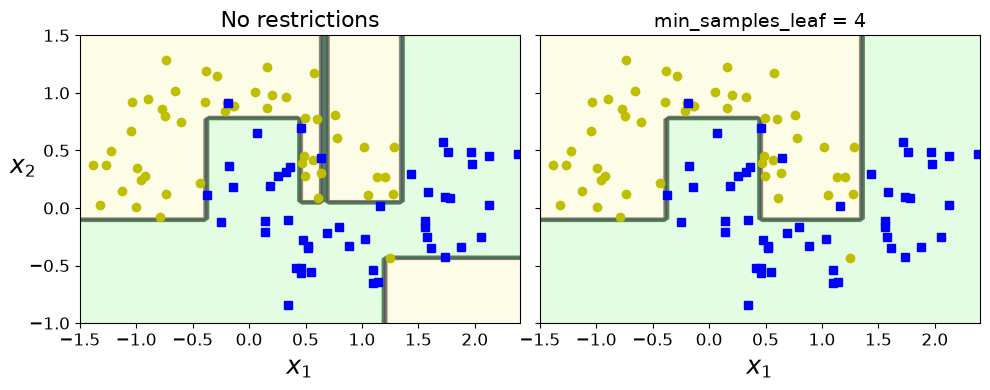

In [21]:
from sklearn.datasets import make_moons
Xm, ym = make_moons(n_samples=100, noise=0.25, random_state=53)

deep_tree_clf1 = DecisionTreeClassifier(random_state=42)
deep_tree_clf2 = DecisionTreeClassifier(min_samples_leaf=4, random_state=42)

deep_tree_clf1.fit(Xm, ym)
deep_tree_clf2.fit(Xm, ym)

fig, axes = plt.subplots(ncols=2, figsize=(10, 4), sharey=True)
plt.sca(axes[0])
plot_decision_boundary(deep_tree_clf1, Xm, ym, axes=[-1.5, 2.4, -1, 1.5], iris=False)
plt.title("No restrictions", fontsize=16)
plt.sca(axes[1])
plot_decision_boundary(deep_tree_clf2, Xm, ym, axes=[-1.5, 2.4, -1, 1.5], iris=False)
plt.title("min_samples_leaf = {}".format(deep_tree_clf2.min_samples_leaf), fontsize=14)
plt.ylabel("")

save_fig("min_samples_leaf_plot")
plt.show()

On the left, you should have a Decision Tree trained with the default hyperparameters (i.e., no restrictions), and on the right, it is trained with `min_samples_leaf`$=4$. It is quite obvious that the model on the left is overfitting, and the model on the right will probably generalize better.

## Regression 

Decision trees can also be used for regression tasks. Instead of predicting a class, in regression tasks, the aim is to predict a numeric value (such as the price of a car). Assume that we have this quadratic data set with some noise:

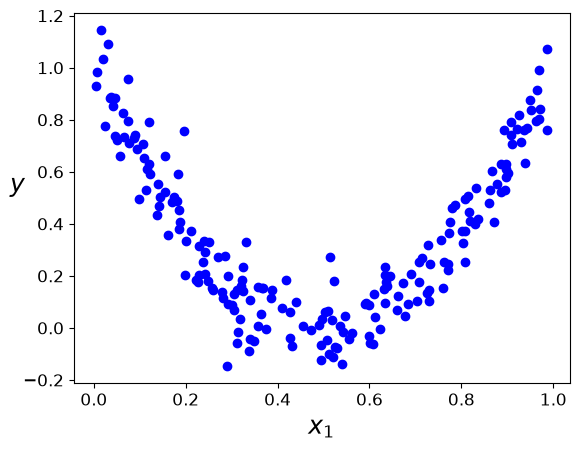

In [31]:
# Quadratic training set + noise
np.random.seed(42)
m = 200
X = np.random.rand(m, 1)
y = 4 * (X - 0.5) ** 2
y = y + np.random.randn(m, 1) / 10

plt.plot(X, y, "bo")
plt.xlabel("$x_{1}$", fontsize=18)
plt.ylabel("$y$", fontsize=18, rotation=0)
plt.show()

In [29]:
from sklearn.tree import DecisionTreeRegressor

tree_reg = DecisionTreeRegressor(max_depth=2, random_state=42)
tree_reg.fit(X, y)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

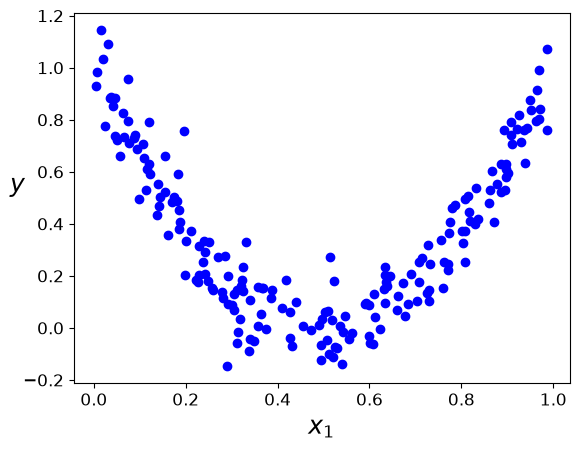

In [30]:
# Quadratic training set + noise
np.random.seed(42)
m = 200
X = np.random.rand(m, 1)
y = 4 * (X - 0.5) ** 2
y = y + np.random.randn(m, 1) / 10

plt.plot(X, y, "bo")
plt.xlabel("$x_{1}$", fontsize=18)
plt.ylabel("$y$", fontsize=18, rotation=0)
plt.show()

This tree should look very similar to the classification tree you built earlier. The main difference is that instead of predicting a class in each node, it predicts a value. For example, if you want to make a prediction for a new instance with x1 = 0.6. You traverse the tree starting at the root, and you eventually reach the leaf node that predicts `value=0.111`. This prediction is the average target value of the 110 training instances associated with this leaf node, and it results in a mean squared error equal to 0.015 over these 110 instances.

You can now experiment with different parameters and see how the resulting decision boundaries vary. Similar to the classification models, regression decision trees also tend to overfit.

In [14]:
# Plot the decision boundaries of two regression trees with max_depth=2 and max_depth=3

from sklearn.tree import DecisionTreeRegressor

tree_reg1 = DecisionTreeRegressor(random_state=42, max_depth=2)
tree_reg2 = DecisionTreeRegressor(random_state=42, max_depth=3)
tree_reg1.fit(X, y)
tree_reg2.fit(X, y)

def plot_regression_predictions(tree_reg, X, y, axes=[0, 1, -0.2, 1], ylabel="$y$"):
    x1 = np.linspace(axes[0], axes[1], 500).reshape(-1, 1)
    y_pred = tree_reg.predict(x1)
    plt.axis(axes)
    plt.xlabel("$x_1$", fontsize=18)
    if ylabel:
        plt.ylabel(ylabel, fontsize=18, rotation=0)
    plt.plot(X, y, "b.")
    plt.plot(x1, y_pred, "r.-", linewidth=2, label=r"$\hat{y}$")

fig, axes = plt.subplots(ncols=2, figsize=(10, 4), sharey=True)
plt.sca(axes[0])
plot_regression_predictions(tree_reg1, X, y)
for split, style in ((0.1973, "k-"), (0.0917, "k--"), (0.7718, "k--")):
    plt.plot([split, split], [-0.2, 1], style, linewidth=2)
plt.text(0.21, 0.65, "Depth=0", fontsize=15)
plt.text(0.01, 0.2, "Depth=1", fontsize=13)
plt.text(0.65, 0.8, "Depth=1", fontsize=13)
plt.legend(loc="upper center", fontsize=18)
plt.title("max_depth=2", fontsize=14)

plt.sca(axes[1])
plot_regression_predictions(tree_reg2, X, y, ylabel=None)
for split, style in ((0.1973, "k-"), (0.0917, "k--"), (0.7718, "k--")):
    plt.plot([split, split], [-0.2, 1], style, linewidth=2)
for split in (0.0458, 0.1298, 0.2873, 0.9040):
    plt.plot([split, split], [-0.2, 1], "k:", linewidth=1)
plt.text(0.3, 0.5, "Depth=2", fontsize=13)
plt.title("max_depth=3", fontsize=14)

save_fig("tree_regression_plot")
plt.show()

Saving figure tree_regression_regularization_plot


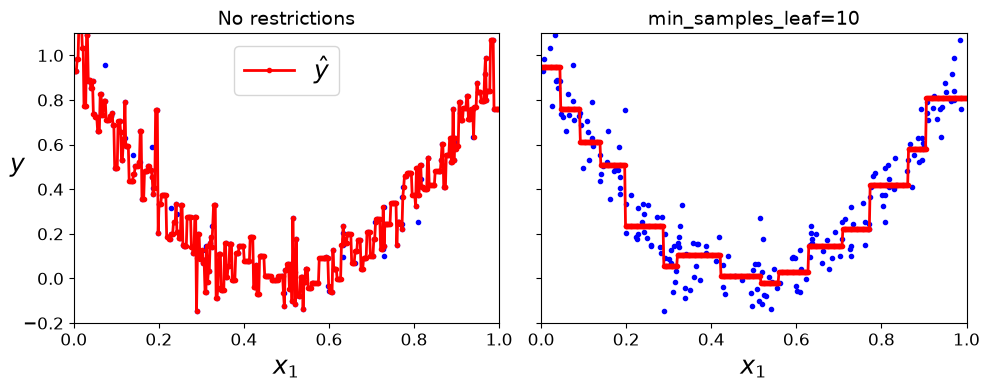

In [32]:
# Plot the decision boundaries of two regression trees - one with 'no restrictions' and one with min_samples_leaf=10

tree_reg1 = DecisionTreeRegressor(random_state=42)
tree_reg2 = DecisionTreeRegressor(random_state=42, min_samples_leaf=10)
tree_reg1.fit(X, y)
tree_reg2.fit(X, y)

x1 = np.linspace(0, 1, 500).reshape(-1, 1)
y_pred1 = tree_reg1.predict(x1)
y_pred2 = tree_reg2.predict(x1)

fig, axes = plt.subplots(ncols=2, figsize=(10, 4), sharey=True)

plt.sca(axes[0])
plt.plot(X, y, "b.")
plt.plot(x1, y_pred1, "r.-", linewidth=2, label=r"$\hat{y}$")
plt.axis([0, 1, -0.2, 1.1])
plt.xlabel("$x_1$", fontsize=18)
plt.ylabel("$y$", fontsize=18, rotation=0)
plt.legend(loc="upper center", fontsize=18)
plt.title("No restrictions", fontsize=14)

plt.sca(axes[1])
plt.plot(X, y, "b.")
plt.plot(x1, y_pred2, "r.-", linewidth=2, label=r"$\hat{y}$")
plt.axis([0, 1, -0.2, 1.1])
plt.xlabel("$x_1$", fontsize=18)
plt.title("min_samples_leaf={}".format(tree_reg2.min_samples_leaf), fontsize=14)

save_fig("tree_regression_regularization_plot")
plt.show()

# Ensemble Learning and Random Forests

Instead of using a single predictor, to improve our predictions we now use _an ensemble_: **a group of predictors**. It is as if you are asking a number of experts for opinions about a problem, and you aggregate their answers.

## Voting Classifiers

A brief comparison between `soft` voting and `hard` voting with using three predictors.

In [33]:
# # Let's use the moons dataset - uncomment and run

from sklearn.model_selection import train_test_split
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=500, noise=0.30, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

Let's test `hard` voting first.

In [17]:
# Uncomment the code below and run

# from sklearn.ensemble import RandomForestClassifier
# from sklearn.ensemble import VotingClassifier
# from sklearn.linear_model import LogisticRegression
# from sklearn.svm import SVC

# log_clf = LogisticRegression(solver="lbfgs", random_state=42)
# rnd_clf = RandomForestClassifier(n_estimators=100, random_state=42)
# svm_clf = SVC(gamma="scale", random_state=42)

# voting_clf = VotingClassifier(
#     estimators=[('lr', log_clf), ('rf', rnd_clf), ('svc', svm_clf)],
#     voting='hard')

In [18]:
# voting_clf.fit(X_train, y_train)

In [19]:
# # To print accuracies

# from sklearn.metrics import accuracy_score

# for clf in (log_clf, rnd_clf, svm_clf, voting_clf):
#     clf.fit(X_train, y_train)
#     y_pred = clf.predict(X_test)
#     print(clf.__class__.__name__, accuracy_score(y_test, y_pred))

Now `soft` voting. All you need to do is replace `voting="hard"` with `voting="soft"` and ensure that all classifiers can estimate class probabilities.

Note: This is not the case for the `SVC` class by default, so you need to set its `probability` hyperparameter to `True` (this will make the `SVC` class use cross-validation to estimate class probabilities, slowing down training, and it will add a `predict_proba()` method).

In [20]:
# Use code blocks from above and replace the required parameters appropriately





In [21]:
# voting_clf.fit(X_train, y_train)

In [22]:
#  print accuracies - use code block from above

_Soft voting_ often achieves higher performance than _hard voting_ because it gives more weight to highly confident votes.

## Bagging & Pasting
Instead of giving training set to each predictor in our ensemble, another approach to gain more accuracy is to separate the training set and give a different training subset to each predictor. There are two ways: 
* **Bagging:** (_bootstrapping in statistics_) picking a random subset from training set and not removing this selected set from training set for each predictor, i.e. **sampling with replacement**
* **Pasting:** picking a random subset from training set and removing this selected set from the training set for each predictor, i.e. **sampling without replacement**
If you are still confused, have a look at [here](http://www.statisticshowto.com/sampling-with-replacement-without/).

Scikit-Learn offers a simple API for both bagging and pasting with the `BaggingClassifier` class (or `BaggingRegressor` for regression). The following code trains an ensemble of 500 Decision Tree classifiers: each is trained on 100 training instances randomly sampled from the training set with replacement (this is an example of bagging, but if you want to use pasting instead, just set `bootstrap=False`). The `n_jobs` parameter tells Scikit-Learn the number of CPU cores to use for training and predictions (`–1` tells Scikit-Learn to use all available cores).

In [23]:
# Uncomment the code below and run

# from sklearn.ensemble import BaggingClassifier
# from sklearn.tree import DecisionTreeClassifier

# bag_clf = BaggingClassifier(
#     DecisionTreeClassifier(), n_estimators=500,
#     max_samples=100, bootstrap=True, random_state=42)
# bag_clf.fit(X_train, y_train)
# y_pred = bag_clf.predict(X_test)

# from sklearn.metrics import accuracy_score
# print("Bagging Classifier Accuracy:")
# print(accuracy_score(y_test, y_pred))

In [24]:
# Uncomment the code below and run

# tree_clf = DecisionTreeClassifier(random_state=42)
# tree_clf.fit(X_train, y_train)
# y_pred_tree = tree_clf.predict(X_test)

# print("Decision Tree Classifier Accuracy:")
# print(accuracy_score(y_test, y_pred_tree))

In [25]:
# #Plotting decision boundaries for a single Decision Tree versus a bagging ensemble of 500 trees 
# Uncomment and run

# from matplotlib.colors import ListedColormap

# def plot_decision_boundary(clf, X, y, axes=[-1.5, 2.45, -1, 1.5], alpha=0.5, contour=True):
#     x1s = np.linspace(axes[0], axes[1], 100)
#     x2s = np.linspace(axes[2], axes[3], 100)
#     x1, x2 = np.meshgrid(x1s, x2s)
#     X_new = np.c_[x1.ravel(), x2.ravel()]
#     y_pred = clf.predict(X_new).reshape(x1.shape)
#     custom_cmap = ListedColormap(['#fafab0','#9898ff','#a0faa0'])
#     plt.contourf(x1, x2, y_pred, alpha=0.3, cmap=custom_cmap)
#     if contour:
#         custom_cmap2 = ListedColormap(['#7d7d58','#4c4c7f','#507d50'])
#         plt.contour(x1, x2, y_pred, cmap=custom_cmap2, alpha=0.8)
#     plt.plot(X[:, 0][y==0], X[:, 1][y==0], "yo", alpha=alpha)
#     plt.plot(X[:, 0][y==1], X[:, 1][y==1], "bs", alpha=alpha)
#     plt.axis(axes)
#     plt.xlabel(r"$x_1$", fontsize=18)
#     plt.ylabel(r"$x_2$", fontsize=18, rotation=0)

In [26]:
# fig, axes = plt.subplots(ncols=2, figsize=(10,4), sharey=True)
# plt.sca(axes[0])
# plot_decision_boundary(tree_clf, X, y)
# plt.title("Decision Tree", fontsize=14)
# plt.sca(axes[1])
# plot_decision_boundary(bag_clf, X, y)
# plt.title("Decision Trees with Bagging", fontsize=14)
# plt.ylabel("")
# save_fig("decision_tree_without_and_with_bagging_plot")
# plt.show()

Try _pasting_ instead of _bagging_ by changing the `bootstrap` parameter. Compare the two models. Which one is better?

Bootstrapping introduces a bit more diversity in the subsets that each predictor is trained on, so bagging ends up with a slightly higher bias than pasting; but the extra diversity also means that the predictors end up being less correlated, so the ensemble’s variance is reduced. Overall, bagging often results in better models, which explains why it is generally preferred. However, if you have spare time and CPU power, you can use cross-validation to evaluate both bagging and pasting and select the one that works best.

## Random Forests

_Random Forest_ is an ensemble of Decision Trees, generally trained via the bagging method (or sometimes pasting), typically with `max_samples` set to the size of the training set. Instead of building a `BaggingClassifier` and passing it a `DecisionTreeClassifier`, you can instead use the `RandomForestClassifier` class, which is more convenient and optimized for Decision Trees.

In [27]:
# Uncomment the code below and run

# from sklearn.ensemble import RandomForestClassifier

# rnd_clf = RandomForestClassifier(n_estimators=500, max_leaf_nodes=16, random_state=42)
# rnd_clf.fit(X_train, y_train)

# y_pred_rf = rnd_clf.predict(X_test)

# # Comparing it to a bag of decision trees

# bag_clf = BaggingClassifier(
#     DecisionTreeClassifier(max_features="sqrt", max_leaf_nodes=16),
#     n_estimators=500, random_state=42)
# bag_clf.fit(X_train, y_train)
# y_pred = bag_clf.predict(X_test)

# # fraction of similar predictions
# np.sum(y_pred == y_pred_rf) / len(y_pred) #highly similar if close to 1

### Feature Importance

A feature’s importance is determined by looking at how much the tree nodes that use that feature reduce impurity on average (across all trees in the forest). More precisely, it is a weighted average, where each node’s weight is equal to the number of training samples that are associated with it.

Scikit-Learn computes this score automatically for each feature after training, then it scales the results so that the sum of all importances is equal to 1. You can access the result using the `feature_importances_` variable.

In [28]:
# from sklearn.datasets import load_iris
# iris = load_iris()
# rnd_clf = RandomForestClassifier(n_estimators=500, random_state=42)
# rnd_clf.fit(iris["data"], iris["target"])
# for name, score in zip(iris["feature_names"], rnd_clf.feature_importances_):
#     print(name, score)

In [29]:
# rnd_clf.feature_importances_

## Boosting

_Boosting_ (originally called _hypothesis boosting_) refers to any Ensemble method that can combine several weak learners into a strong learner. The general idea is to train predictors sequentially, each trying to correct its predecessor.

### AdaBoost

One way for a new predictor to correct its predecessor is to pay a bit more attention to the training instances that the predecessor underfitted. This results in new predictors focusing more and more on the hard cases. This is the technique used by AdaBoost.

In [30]:
## Uncomment the code below and run

# from sklearn.ensemble import AdaBoostClassifier

# ada_clf = AdaBoostClassifier(
#     DecisionTreeClassifier(max_depth=1), n_estimators=200)
# ada_clf.fit(X_train, y_train)

In [31]:
# plot_decision_boundary(ada_clf, X, y)

In [32]:
# Decision boundaries of consecutive predictors - Uncomment and run

# m = len(X_train)

# fix, axes = plt.subplots(ncols=2, figsize=(10,4), sharey=True)
# for subplot, learning_rate in ((0, 1), (1, 0.5)):
#     sample_weights = np.ones(m) / m
#     plt.sca(axes[subplot])
#     for i in range(5):
#         svm_clf = SVC(kernel="rbf", C=0.2, gamma=0.6, random_state=42)
#         svm_clf.fit(X_train, y_train, sample_weight=sample_weights * m)
#         y_pred = svm_clf.predict(X_train)

#         r = sample_weights[y_pred != y_train].sum() / sample_weights.sum() # equation 7-1
#         alpha = learning_rate * np.log((1 - r) / r) # equation 7-2
#         sample_weights[y_pred != y_train] *= np.exp(alpha) # equation 7-3
#         sample_weights /= sample_weights.sum() # normalization step

#         plot_decision_boundary(svm_clf, X, y, alpha=0.2)
#         plt.title("learning_rate = {}".format(learning_rate), fontsize=16)
#     if subplot == 0:
#         plt.text(-0.75, -0.95, "1", fontsize=14)
#         plt.text(-1.05, -0.95, "2", fontsize=14)
#         plt.text(1.0, -0.95, "3", fontsize=14)
#         plt.text(-1.45, -0.5, "4", fontsize=14)
#         plt.text(1.36,  -0.95, "5", fontsize=14)
#     else:
#         plt.ylabel("")

# save_fig("boosting_plot")
# plt.show()

The above figure shows the decision boundaries of five consecutive predictors (here, they are highly regularized SVM classifier with an RBF kernels) on the moons dataset. The first classifier gets many instances wrong, so its weights get boosted. The second classifier, therefore, does a better job on these instances, and so on. The plot on the right represents the same sequence of predictors, except that the learning rate is halved (i.e., the misclassified instance weights are boosted much less at every iteration). As you can see, this sequential learning technique has some similarities with Gradient Descent, except that instead of tweaking a single predictor’s parameters to minimize a cost function, AdaBoost adds predictors to the ensemble, gradually making it better.

## Gradient Boosting

Just like AdaBoost, Gradient Boosting works by sequentially adding predictors to an ensemble, each one correcting its predecessor. However, instead of tweaking the instance weights at every iteration like AdaBoost does, this method tries to fit the new predictor to the residual errors made by the previous predictor.

In [33]:
# # Let create a simple quadratic dataset

# np.random.seed(42)
# X = np.random.rand(100, 1) - 0.5
# y = 3*X[:, 0]**2 + 0.05 * np.random.randn(100)

# # Now let's train a decision tree regressor on this dataset

# from sklearn.tree import DecisionTreeRegressor

# tree_reg1 = DecisionTreeRegressor(max_depth=2, random_state=42)
# tree_reg1.fit(X, y)

In [34]:
# # Next, we’ll train a second DecisionTreeRegressor on the residual errors made by the first predictor:

# y2 = y - tree_reg1.predict(X)
# tree_reg2 =            #Use command to define anothe decision tree similar to tree_reg1
# tree_reg2.fit(X, y2)

In [35]:
# # and so on

# y3 = y2 - tree_reg2.predict(X)
# tree_reg3 = 
# tree_reg3.fit(X, y3)

In [36]:
# X_new = np.array([[0.8]])
# y_pred = sum(tree.predict(X_new) for tree in (tree_reg1, tree_reg2, tree_reg3))
# y_pred

A simpler way to train GBRT ensembles is to use Scikit-Learn’s `GradientBoostingRegressor` class. Much like the `RandomForestRegressor` class, it has hyperparameters to control the growth of Decision Trees (e.g., `max_depth`, `min_samples_leaf`), as well as hyperparameters to control the ensemble training, such as the number of trees (`n_estimators`).

In [37]:
# Uncomment the code below and run

# from sklearn.ensemble import GradientBoostingRegressor

# gbrt = GradientBoostingRegressor(max_depth=2, n_estimators=3, learning_rate=1.0, random_state=42)
# gbrt.fit(X, y)

The `learning_rate` hyperparameter scales the contribution of each tree. If you set it to a low value, such as `0.1`, you will need more trees in the ensemble to fit the training set.

In [38]:
# gbrt_slow = GradientBoostingRegressor(max_depth=2, n_estimators=200, learning_rate=0.1, random_state=42)
# gbrt_slow.fit(X, y)

In [39]:
# def plot_predictions(regressors, X, y, axes, label=None, style="r-", data_style="b.", data_label=None):
#     x1 = np.linspace(axes[0], axes[1], 500)
#     y_pred = sum(regressor.predict(x1.reshape(-1, 1)) for regressor in regressors)
#     plt.plot(X[:, 0], y, data_style, label=data_label)
#     plt.plot(x1, y_pred, style, linewidth=2, label=label)
#     if label or data_label:
#         plt.legend(loc="upper center", fontsize=16)
#     plt.axis(axes)

In [40]:
# fix, axes = plt.subplots(ncols=2, figsize=(10,4), sharey=True)

# plt.sca(axes[0])
# plot_predictions([gbrt], X, y, axes=[-0.5, 0.5, -0.1, 0.8], label="Ensemble predictions")
# plt.title("learning_rate={}, n_estimators={}".format(gbrt.learning_rate, gbrt.n_estimators), fontsize=14)
# plt.xlabel("$x_1$", fontsize=16)
# plt.ylabel("$y$", fontsize=16, rotation=0)

# plt.sca(axes[1])
# plot_predictions([gbrt_slow], X, y, axes=[-0.5, 0.5, -0.1, 0.8])
# plt.title("learning_rate={}, n_estimators={}".format(gbrt_slow.learning_rate, gbrt_slow.n_estimators), fontsize=14)
# plt.xlabel("$x_1$", fontsize=16)

# save_fig("gbrt_learning_rate_plot")
# plt.show()

The above figure shows two GBRT ensembles trained with a low learning rate: the one on the left does not have enough trees to fit the training set, while the one on the right has too many trees and overfits the training set.

In order to find the optimal number of trees, you can use _early stopping_. A simple way to implement this is to use the `staged_predict()` method: it returns an iterator over the predictions made by the ensemble at each stage of training (with one tree, two trees, etc.). 

The following code trains a GBRT ensemble with 120 trees, then measures the validation error at each stage of training to find the optimal number of trees, and finally trains another GBRT ensemble using the optimal number of trees.

In [41]:
# Uncomment the code below and run

# import numpy as np
# from sklearn.model_selection import train_test_split
# from sklearn.metrics import mean_squared_error

# X_train, X_val, y_train, y_val = train_test_split(X, y, random_state=49)

# gbrt = GradientBoostingRegressor(max_depth=2, n_estimators=120, random_state=42)
# gbrt.fit(X_train, y_train)

# errors = [mean_squared_error(y_val, y_pred)
#           for y_pred in gbrt.staged_predict(X_val)]
# bst_n_estimators = np.argmin(errors) + 1

# gbrt_best = GradientBoostingRegressor(max_depth=2, n_estimators=bst_n_estimators, random_state=42)
# gbrt_best.fit(X_train, y_train)

In [42]:
# min_error = np.min(errors)

# plt.figure(figsize=(10, 4))

# plt.subplot(121)
# plt.plot(np.arange(1, len(errors) + 1), errors, "b.-")
# plt.plot([bst_n_estimators, bst_n_estimators], [0, min_error], "k--")
# plt.plot([0, 120], [min_error, min_error], "k--")
# plt.plot(bst_n_estimators, min_error, "ko")
# plt.text(bst_n_estimators, min_error*1.2, "Minimum", ha="center", fontsize=14)
# plt.axis([0, 120, 0, 0.01])
# plt.xlabel("Number of trees")
# plt.ylabel("Error", fontsize=16)
# plt.title("Validation error", fontsize=14)

# plt.subplot(122)
# plot_predictions([gbrt_best], X, y, axes=[-0.5, 0.5, -0.1, 0.8])
# plt.title("Best model (%d trees)" % bst_n_estimators, fontsize=14)
# plt.ylabel("$y$", fontsize=16, rotation=0)
# plt.xlabel("$x_1$", fontsize=16)

# save_fig("early_stopping_gbrt_plot")
# plt.show()

### Using XGBoost

It is worth noting that an optimized implementation of Gradient Boosting is available in the popular Python library [XGBoost](https://github.com/dmlc/xgboost), which stands for Extreme Gradient Boosting. It is most likely not installed in the lab PC machines. But you can try it on your own.

## Recap

At this point, we demonstrated these concepts:

* training and visualizing various models from Decision Trees and Ensemble Learning
* details about some hyperparameters and how to regularize the models
* different training methods for ensemble learning
* how a boosting technique works and its properties.

Of course, there are some material that we have not be able to cover. In your free time, it can be better to have a look at:

* **Decision Trees**
  * How hard is it to find the best split to construct the _optimal tree_? 
  * Why is CART algorithm called _a greedy algorithm_?
* **Ensemble Learning and Random Forests**
  * Difference between Extra-Trees and Random Forests
  * How does AdaBoost work?
  * Learning Feature Importance with Random Forests
  * What is `Stacking`?
  * Using XGBoost package to implement Gradient Boosting.